# Acrobot Reinforcement Learning Comparison

This notebook implements and compares **Q-Learning, DQN, and PPO from scratch**
on Gymnasium's `Acrobot-v1`. It does not use Stable-Baselines3 or another
ready-made reinforcement-learning algorithm.

Run the cells from top to bottom. For a faculty presentation, use the quick
configuration first, then show the repository's completed 111-run research study.
The notebook is the portable demo; `run_study.py` is the complete experiment
runner with tuning, held-out evaluation, sweeps, ablations, and bootstrap CIs.

## 1. Problem and experimental design

- **Observation:** 6 continuous values describing joint-angle sine/cosine values and angular velocities.
- **Action:** one of 3 torques: negative, zero, or positive.
- **Reward:** -1 per step until the target height is reached.
- **Fairness:** every algorithm receives the same environment-interaction budget.
- **Evaluation:** exploration is disabled and the same evaluation protocol is used for all methods.
- **Reproducibility:** Python, NumPy, PyTorch, exploration, and Gymnasium are seeded.

## 2. From-scratch implementation

In [1]:
"""Single-file Google Colab edition of the Acrobot RL comparison.

Run from a terminal with Google's official Colab CLI:
    colab run --gpu T4 colab/acrobot_colab.py --budget 100000 --seeds 0 1 2 3 4

Or upload this file to colab.research.google.com and run:
    %run acrobot_colab.py --budget 100000 --seeds 0 1 2 3 4

The file is deliberately self-contained: Q-Learning, DQN, and PPO are implemented
below without Stable-Baselines3 or another ready-made RL implementation.
"""

from __future__ import annotations

import argparse
import importlib.util
import random
import subprocess
import sys
import time
from collections import deque
from pathlib import Path


def install_missing_dependencies() -> None:
    packages = {
        "gymnasium": "gymnasium[classic-control]>=1.0,<2.0",
        "matplotlib": "matplotlib>=3.9,<4.0",
        "pandas": "pandas>=2.2,<3.0",
        "torch": "torch>=2.4,<3.0",
    }
    missing = [package for module, package in packages.items() if importlib.util.find_spec(module) is None]
    if missing:
        print("Installing missing packages:", ", ".join(missing))
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])


install_missing_dependencies()

import gymnasium as gym
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from torch import nn
from torch.distributions import Categorical


ENV_ID = "Acrobot-v1"
MAX_EPISODE_STEPS = 500
OBSERVATION_DIM = 6
ACTION_COUNT = 3


def seed_everything(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


def choose_device() -> torch.device:
    if torch.cuda.is_available():
        return torch.device("cuda")
    if hasattr(torch.backends, "mps") and torch.backends.mps.is_available():
        return torch.device("mps")
    return torch.device("cpu")


class Discretizer:
    """Map Acrobot's angle encodings and velocities to a finite table index."""

    LOW = np.array([-1, -1, -1, -1, -4 * np.pi, -9 * np.pi], dtype=np.float32)
    HIGH = np.array([1, 1, 1, 1, 4 * np.pi, 9 * np.pi], dtype=np.float32)

    def __init__(self, bins: tuple[int, ...] = (6, 6, 6, 6, 8, 8)):
        self.bins = bins
        self.width = (self.HIGH - self.LOW) / np.asarray(bins)

    def encode(self, observation: np.ndarray) -> tuple[int, ...]:
        index = np.floor((np.asarray(observation) - self.LOW) / self.width).astype(int)
        return tuple(np.clip(index, 0, np.asarray(self.bins) - 1).tolist())


class QLearning:
    def __init__(self, seed: int):
        self.discretizer = Discretizer()
        self.q = np.zeros((*self.discretizer.bins, ACTION_COUNT), dtype=np.float32)
        self.rng = np.random.default_rng(seed)
        self.alpha = 0.1
        self.gamma = 0.99

    @staticmethod
    def epsilon(step: int, budget: int) -> float:
        return 1.0 - min(step / max(0.75 * budget, 1), 1.0) * 0.95

    def act(self, observation: np.ndarray, epsilon: float = 0.0, deterministic: bool = False) -> int:
        if self.rng.random() < epsilon:
            return int(self.rng.integers(ACTION_COUNT))
        values = self.q[self.discretizer.encode(observation)]
        if deterministic:
            return int(np.argmax(values))
        best = np.flatnonzero(values == values.max())
        return int(self.rng.choice(best))

    def update(self, observation, action, reward, next_observation, terminated) -> float:
        state = self.discretizer.encode(observation)
        next_state = self.discretizer.encode(next_observation)
        old = float(self.q[state + (action,)])
        bootstrap = 0.0 if terminated else float(self.q[next_state].max())
        error = reward + self.gamma * bootstrap - old
        self.q[state + (action,)] = old + self.alpha * error
        return error


def mlp(input_size: int, output_size: int, hidden: tuple[int, ...]) -> nn.Sequential:
    layers: list[nn.Module] = []
    previous = input_size
    for size in hidden:
        layers += [nn.Linear(previous, size), nn.Tanh()]
        previous = size
    layers.append(nn.Linear(previous, output_size))
    return nn.Sequential(*layers)


class ReplayBuffer:
    def __init__(self, capacity: int, seed: int):
        self.data = deque(maxlen=capacity)
        self.rng = np.random.default_rng(seed)

    def add(self, *transition) -> None:
        self.data.append(transition)

    def sample(self, size: int):
        indices = self.rng.choice(len(self.data), size=size, replace=False)
        columns = zip(*(self.data[index] for index in indices))
        observation, action, reward, next_observation, terminated = columns
        return (
            np.asarray(observation, dtype=np.float32),
            np.asarray(action, dtype=np.int64),
            np.asarray(reward, dtype=np.float32),
            np.asarray(next_observation, dtype=np.float32),
            np.asarray(terminated, dtype=np.float32),
        )

    def __len__(self) -> int:
        return len(self.data)


class DQN:
    def __init__(self, seed: int, device: torch.device):
        self.device = device
        self.rng = np.random.default_rng(seed)
        self.online = mlp(OBSERVATION_DIM, ACTION_COUNT, (128, 128)).to(device)
        self.target = mlp(OBSERVATION_DIM, ACTION_COUNT, (128, 128)).to(device)
        self.target.load_state_dict(self.online.state_dict())
        self.optimizer = torch.optim.Adam(self.online.parameters(), lr=1e-3)
        self.gamma = 0.99

    @staticmethod
    def epsilon(step: int, budget: int) -> float:
        return 1.0 - min(step / max(0.75 * budget, 1), 1.0) * 0.95

    @torch.no_grad()
    def act(self, observation: np.ndarray, epsilon: float = 0.0) -> int:
        if self.rng.random() < epsilon:
            return int(self.rng.integers(ACTION_COUNT))
        state = torch.as_tensor(observation, dtype=torch.float32, device=self.device).unsqueeze(0)
        return int(self.online(state).argmax(1).item())

    def learn(self, batch) -> float:
        observation, action, reward, next_observation, terminated = batch
        observation = torch.as_tensor(observation, device=self.device)
        action = torch.as_tensor(action, device=self.device).unsqueeze(1)
        reward = torch.as_tensor(reward, device=self.device)
        next_observation = torch.as_tensor(next_observation, device=self.device)
        terminated = torch.as_tensor(terminated, device=self.device)
        prediction = self.online(observation).gather(1, action).squeeze(1)
        with torch.no_grad():
            target = reward + self.gamma * (1 - terminated) * self.target(next_observation).max(1).values
        loss = nn.functional.smooth_l1_loss(prediction, target)
        self.optimizer.zero_grad()
        loss.backward()
        nn.utils.clip_grad_norm_(self.online.parameters(), 10.0)
        self.optimizer.step()
        return float(loss.item())

    def sync(self) -> None:
        self.target.load_state_dict(self.online.state_dict())


class ActorCritic(nn.Module):
    def __init__(self):
        super().__init__()
        self.actor = mlp(OBSERVATION_DIM, ACTION_COUNT, (64, 64))
        self.critic = mlp(OBSERVATION_DIM, 1, (64, 64))

    def distribution(self, states: torch.Tensor) -> Categorical:
        return Categorical(logits=self.actor(states))

    def value(self, states: torch.Tensor) -> torch.Tensor:
        return self.critic(states).squeeze(-1)


def generalized_advantage_estimation(
    rewards, values, next_values, terminated, done, gamma=0.99, gae_lambda=0.95
):
    advantages = np.zeros_like(rewards, dtype=np.float32)
    gae = 0.0
    for index in reversed(range(len(rewards))):
        delta = rewards[index] + gamma * (1 - terminated[index]) * next_values[index] - values[index]
        gae = delta + gamma * gae_lambda * (1 - done[index]) * gae
        advantages[index] = gae
    return advantages, advantages + values


class PPO:
    def __init__(self, seed: int, device: torch.device):
        self.device = device
        self.rng = np.random.default_rng(seed)
        self.network = ActorCritic().to(device)
        self.optimizer = torch.optim.Adam(self.network.parameters(), lr=3e-4)

    @torch.no_grad()
    def act(self, observation, deterministic=False):
        state = torch.as_tensor(observation, dtype=torch.float32, device=self.device).unsqueeze(0)
        distribution = self.network.distribution(state)
        action = distribution.probs.argmax(-1) if deterministic else distribution.sample()
        return int(action.item()), float(distribution.log_prob(action).item()), float(self.network.value(state).item())

    @torch.no_grad()
    def value(self, observation) -> float:
        state = torch.as_tensor(observation, dtype=torch.float32, device=self.device).unsqueeze(0)
        return float(self.network.value(state).item())

    def update(self, rollout, epochs=5, minibatch_size=64) -> float:
        states = torch.as_tensor(rollout["states"], dtype=torch.float32, device=self.device)
        actions = torch.as_tensor(rollout["actions"], dtype=torch.int64, device=self.device)
        old_logs = torch.as_tensor(rollout["logs"], dtype=torch.float32, device=self.device)
        returns = torch.as_tensor(rollout["returns"], dtype=torch.float32, device=self.device)
        advantages = torch.as_tensor(rollout["advantages"], dtype=torch.float32, device=self.device)
        advantages = (advantages - advantages.mean()) / (advantages.std(unbiased=False) + 1e-8)
        losses = []
        for _ in range(epochs):
            permutation = self.rng.permutation(len(states))
            for start in range(0, len(states), minibatch_size):
                index = torch.as_tensor(permutation[start:start + minibatch_size], device=self.device)
                distribution = self.network.distribution(states[index])
                new_logs = distribution.log_prob(actions[index])
                ratio = (new_logs - old_logs[index]).exp()
                surrogate = torch.minimum(
                    ratio * advantages[index],
                    torch.clamp(ratio, 0.8, 1.2) * advantages[index],
                )
                policy_loss = -surrogate.mean()
                value_loss = nn.functional.mse_loss(self.network.value(states[index]), returns[index])
                loss = policy_loss + 0.5 * value_loss - 0.01 * distribution.entropy().mean()
                self.optimizer.zero_grad()
                loss.backward()
                nn.utils.clip_grad_norm_(self.network.parameters(), 0.5)
                self.optimizer.step()
                losses.append(float(policy_loss.item()))
        return float(np.mean(losses))


def episode_record(algorithm, seed, episode, steps, reward, length, success, loss, elapsed):
    return {
        "algorithm": algorithm, "seed": seed, "episode": episode,
        "environment_steps": steps, "episode_return": reward,
        "episode_length": length, "success": int(success), "loss": loss,
        "elapsed_seconds": elapsed,
    }


def train_q_learning(seed: int, budget: int):
    seed_everything(seed)
    env = gym.make(ENV_ID, max_episode_steps=MAX_EPISODE_STEPS)
    env.action_space.seed(seed)
    agent = QLearning(seed)
    records, steps, episode = [], 0, 0
    started = time.perf_counter()
    while steps < budget:
        observation, _ = env.reset(seed=seed + episode)
        reward_sum, length, errors = 0.0, 0, []
        terminated = truncated = False
        while not (terminated or truncated) and steps < budget:
            action = agent.act(observation, agent.epsilon(steps, budget))
            next_observation, reward, terminated, truncated, _ = env.step(action)
            errors.append(agent.update(observation, action, reward, next_observation, terminated))
            observation, steps = next_observation, steps + 1
            reward_sum, length = reward_sum + reward, length + 1
        if terminated or truncated:
            records.append(episode_record("q_learning", seed, episode, steps, reward_sum, length, terminated, np.mean(np.abs(errors)), time.perf_counter() - started))
        episode += 1
    env.close()
    return agent, records


def train_dqn(seed: int, budget: int, device: torch.device):
    seed_everything(seed)
    env = gym.make(ENV_ID, max_episode_steps=MAX_EPISODE_STEPS)
    env.action_space.seed(seed)
    agent, replay = DQN(seed, device), ReplayBuffer(100_000, seed)
    records, steps, episode = [], 0, 0
    learning_starts = min(1_000, max(64, budget // 5))
    started = time.perf_counter()
    while steps < budget:
        observation, _ = env.reset(seed=seed + episode)
        reward_sum, length, losses = 0.0, 0, []
        terminated = truncated = False
        while not (terminated or truncated) and steps < budget:
            action = agent.act(observation, agent.epsilon(steps, budget))
            next_observation, reward, terminated, truncated, _ = env.step(action)
            replay.add(observation, action, reward, next_observation, terminated)
            observation, steps = next_observation, steps + 1
            reward_sum, length = reward_sum + reward, length + 1
            if steps >= learning_starts and steps % 4 == 0 and len(replay) >= 64:
                losses.append(agent.learn(replay.sample(64)))
            if steps % 1_000 == 0:
                agent.sync()
        if terminated or truncated:
            records.append(episode_record("dqn", seed, episode, steps, reward_sum, length, terminated, np.mean(losses) if losses else np.nan, time.perf_counter() - started))
        episode += 1
    env.close()
    return agent, records


def train_ppo(seed: int, budget: int, device: torch.device):
    seed_everything(seed)
    env = gym.make(ENV_ID, max_episode_steps=MAX_EPISODE_STEPS)
    env.action_space.seed(seed)
    agent = PPO(seed, device)
    records, steps, episode = [], 0, 0
    reward_sum, length = 0.0, 0
    observation, _ = env.reset(seed=seed)
    started = time.perf_counter()
    while steps < budget:
        size = min(1_024, budget - steps)
        data = {key: [] for key in ("states", "actions", "rewards", "logs", "values", "next_values", "terminated", "done")}
        completed = []
        for _ in range(size):
            action, log_probability, value = agent.act(observation)
            next_observation, reward, terminated, truncated, _ = env.step(action)
            done = terminated or truncated
            data["states"].append(observation)
            data["actions"].append(action)
            data["rewards"].append(reward)
            data["logs"].append(log_probability)
            data["values"].append(value)
            data["next_values"].append(0.0 if terminated else agent.value(next_observation))
            data["terminated"].append(float(terminated))
            data["done"].append(float(done))
            observation, steps = next_observation, steps + 1
            reward_sum, length = reward_sum + reward, length + 1
            if done:
                records.append(episode_record("ppo", seed, episode, steps, reward_sum, length, terminated, np.nan, time.perf_counter() - started))
                completed.append(len(records) - 1)
                episode += 1
                reward_sum, length = 0.0, 0
                observation, _ = env.reset(seed=seed + episode)
        arrays = {key: np.asarray(value, dtype=np.float32) for key, value in data.items()}
        advantages, returns = generalized_advantage_estimation(
            arrays["rewards"], arrays["values"], arrays["next_values"],
            arrays["terminated"], arrays["done"],
        )
        loss = agent.update({
            "states": arrays["states"], "actions": arrays["actions"],
            "logs": arrays["logs"], "returns": returns, "advantages": advantages,
        })
        for index in completed:
            records[index]["loss"] = loss
    env.close()
    return agent, records


def evaluate(agent, algorithm: str, seed: int, episodes: int):
    env = gym.make(ENV_ID, max_episode_steps=MAX_EPISODE_STEPS)
    records = []
    for episode in range(episodes):
        observation, _ = env.reset(seed=10_000 + seed + episode)
        terminated = truncated = False
        reward_sum, length = 0.0, 0
        while not (terminated or truncated):
            if algorithm == "q_learning":
                action = agent.act(observation, deterministic=True)
            elif algorithm == "dqn":
                action = agent.act(observation)
            else:
                action = agent.act(observation, deterministic=True)[0]
            observation, reward, terminated, truncated, _ = env.step(action)
            reward_sum, length = reward_sum + reward, length + 1
        records.append({
            "algorithm": algorithm, "seed": seed, "episode": episode,
            "episode_return": reward_sum, "episode_length": length,
            "success": int(terminated),
        })
    env.close()
    return records


def smoke_test() -> None:
    env = gym.make(ENV_ID)
    observation, _ = env.reset(seed=0)
    assert observation.shape == (OBSERVATION_DIM,)
    assert env.action_space.n == ACTION_COUNT
    env.step(0)
    env.close()
    advantages, returns = generalized_advantage_estimation(
        np.array([1, 1], dtype=np.float32), np.array([0.5, 0.5], dtype=np.float32),
        np.array([0.5, 99], dtype=np.float32), np.array([0, 1], dtype=np.float32),
        np.array([0, 1], dtype=np.float32), gamma=1, gae_lambda=1,
    )
    np.testing.assert_allclose(advantages, [1.5, 0.5])
    print("Smoke test passed: observation=(6,), actions=3, GAE terminal mask correct")


def plot_results(training: pd.DataFrame, evaluation: pd.DataFrame, output: Path) -> None:
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    for algorithm, group in training.groupby("algorithm"):
        ordered = group.sort_values("environment_steps")
        axes[0].plot(ordered["environment_steps"], ordered["episode_return"].rolling(20, min_periods=1).mean(), label=algorithm)
    evaluation.groupby("algorithm")["episode_return"].mean().plot.bar(ax=axes[1])
    evaluation.groupby("algorithm")["success"].mean().plot.bar(ax=axes[2])
    axes[0].set(title="Training return", xlabel="Environment interactions", ylabel="20-episode mean")
    axes[1].set(title="Mean evaluation return", ylabel="Return")
    axes[2].set(title="Evaluation success rate", ylabel="Fraction")
    axes[0].legend()
    for axis in axes:
        axis.grid(alpha=0.25)
    fig.tight_layout()
    fig.savefig(output, dpi=180)
    try:
        from IPython.display import display
        display(fig)
    except ImportError:
        pass
    plt.close(fig)


def run_comparison(budget: int, seeds: list[int], eval_episodes: int, output: Path) -> None:
    output.mkdir(parents=True, exist_ok=True)
    device = choose_device()
    print(f"Device: {device}; budget per algorithm/seed: {budget:,}")
    training_records, evaluation_records = [], []
    trainers = {
        "q_learning": lambda seed: train_q_learning(seed, budget),
        "dqn": lambda seed: train_dqn(seed, budget, device),
        "ppo": lambda seed: train_ppo(seed, budget, device),
    }
    for seed in seeds:
        for algorithm, trainer in trainers.items():
            print(f"Training {algorithm}, seed {seed}...")
            started = time.perf_counter()
            agent, records = trainer(seed)
            training_seconds = time.perf_counter() - started
            evaluations = evaluate(agent, algorithm, seed, eval_episodes)
            for record in evaluations:
                record["training_seconds"] = training_seconds
                record["environment_interactions"] = budget
            training_records.extend(records)
            evaluation_records.extend(evaluations)
            if algorithm == "q_learning":
                np.savez_compressed(output / f"{algorithm}_seed{seed}.npz", q_table=agent.q)
            elif algorithm == "dqn":
                torch.save(agent.online.state_dict(), output / f"{algorithm}_seed{seed}.pt")
            else:
                torch.save(agent.network.state_dict(), output / f"{algorithm}_seed{seed}.pt")
    training = pd.DataFrame(training_records)
    evaluation = pd.DataFrame(evaluation_records)
    training.to_csv(output / "training.csv", index=False)
    evaluation.to_csv(output / "evaluation.csv", index=False)
    summary = evaluation.groupby("algorithm").agg(
        mean_return=("episode_return", "mean"),
        median_return=("episode_return", "median"),
        return_std=("episode_return", "std"),
        success_rate=("success", "mean"),
        mean_steps=("episode_length", "mean"),
        training_seconds=("training_seconds", "mean"),
        seeds=("seed", "nunique"),
    )
    summary.to_csv(output / "summary.csv")
    plot_results(training, evaluation, output / "comparison.png")
    print("\nEvaluation summary (actual run data):")
    print(summary.to_string())
    print(f"\nSaved models, raw CSVs, and plot in: {output.resolve()}")


def parse_args():
    parser = argparse.ArgumentParser(description=__doc__)
    parser.add_argument("--mode", choices=("smoke", "compare"), default="compare")
    parser.add_argument("--budget", type=int, default=10_000, help="Interactions per algorithm and seed")
    parser.add_argument("--seeds", nargs="+", type=int, default=[0])
    parser.add_argument("--eval-episodes", type=int, default=5)
    parser.add_argument("--output", type=Path, default=Path("acrobot_colab_results"))
    arguments, unknown = parser.parse_known_args()
    return arguments



## 3. Choose experiment size

Use 2,000 interactions and one seed only to verify that everything runs. For the
final report, use at least 100,000 interactions and five seeds. A full experiment
can take a long time, so run it before your presentation.

In [2]:
#@title Experiment configuration
BUDGET = 100000 #@param {type:"integer"}
SEEDS = [0] #@param
EVALUATION_EPISODES = 10 #@param {type:"integer"}
OUTPUT_DIRECTORY = Path('results/notebook_demo')

print(f'Budget: {BUDGET:,} interactions per algorithm and seed')
print(f'Seeds: {SEEDS}')
print(f'Device: {choose_device()}')

Budget: 100,000 interactions per algorithm and seed
Seeds: [0]
Device: mps


## 4. Verify mathematical components

In [3]:
smoke_test()

Smoke test passed: observation=(6,), actions=3, GAE terminal mask correct


## 5. Train and compare

This cell trains all three agents, evaluates them without exploration, saves raw
CSV data and checkpoints, and generates a comparison plot. Short runs validate
the pipeline but are not valid evidence that one algorithm is better.

Device: mps; budget per algorithm/seed: 100,000
Training q_learning, seed 0...


Training dqn, seed 0...


Training ppo, seed 0...


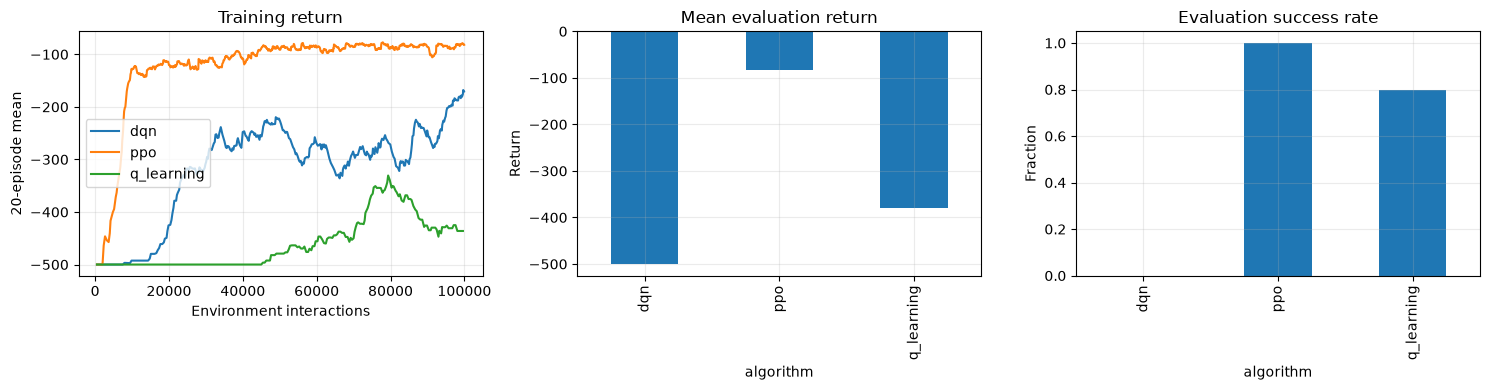


Evaluation summary (actual run data):
            mean_return  median_return  return_std  success_rate  mean_steps  training_seconds  seeds
algorithm                                                                                            
dqn              -500.0         -500.0    0.000000           0.0       500.0         87.535905      1
ppo               -82.2          -84.0    7.192589           1.0        83.2        219.230252      1
q_learning       -380.2         -391.0   89.209865           0.8       381.0          3.217285      1

Saved models, raw CSVs, and plot in: /Users/meetmehta/Desktop/Acrobot/results/notebook_demo


In [4]:
run_comparison(BUDGET, SEEDS, EVALUATION_EPISODES, OUTPUT_DIRECTORY)

## 6. Inspect the raw evidence

,algorithm,mean_return,median_return,return_std,success_rate,mean_steps,training_seconds,seeds
0,dqn,-500.0,-500.0,0.000000,0.0,500.0,87.535905,1
1,ppo,-82.2,-84.0,7.192589,1.0,83.2,219.230252,1
2,q_learning,-380.2,-391.0,89.209865,0.8,381.0,3.217285,1


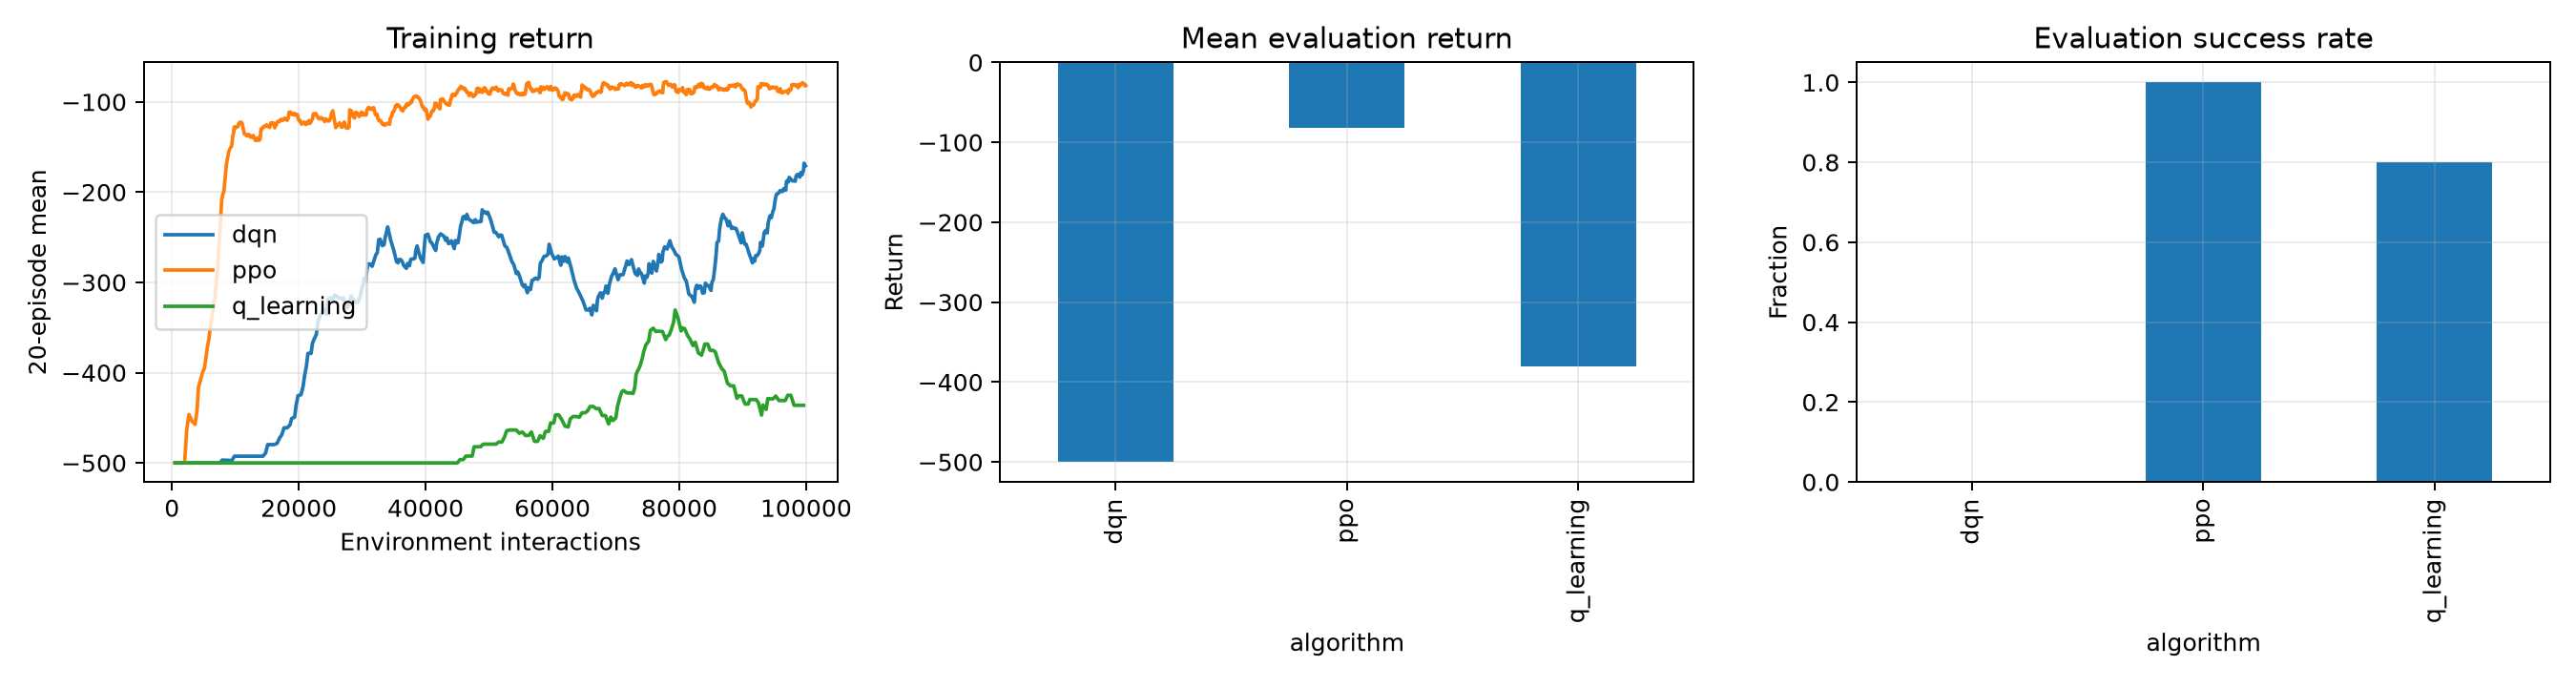

Raw files: ['comparison.png', 'dqn_seed0.pt', 'evaluation.csv', 'ppo_seed0.pt', 'q_learning_seed0.npz', 'summary.csv', 'training.csv']


In [5]:
from IPython.display import Image

summary = pd.read_csv(OUTPUT_DIRECTORY / 'summary.csv')
display(summary)
display(Image(filename=str(OUTPUT_DIRECTORY / 'comparison.png')))
print('Raw files:', sorted(path.name for path in OUTPUT_DIRECTORY.iterdir()))

## Faculty demonstration checklist

1. Explain why Acrobot is underactuated.
2. Identify the six observations, three actions, and -1 step reward.
3. Show Q-Learning's discretizer and Bellman update.
4. Show DQN's replay buffer and target network.
5. Show PPO's actor, critic, GAE, and clipped objective.
6. Explain why equal interaction budgets are fairer than equal episode counts.
7. Present evaluation return, success rate, stability across seeds, and training time.
8. Open the raw CSV to prove that the plots use actual experiment data.
9. State limitations: discretization error, seed sensitivity, and finite training budget.

The completed local study found PPO to be the only reliable solver at 100,000
interactions: final held-out return IQM -81.7 and success IQM 100% across five
seeds. DQN was seed-sensitive and Q-Learning did not reliably solve within the
budget. Present this as a conditional result, not a universal algorithm ranking.